# 02 — Feature engineering, training & tracking
The pipeline is median impute + StandardScaler for numeric columns and mode impute + OneHotEncoder for categorical columns. Two models are tuned with GridSearchCV (5-fold stratified, scored on ROC-AUC), and every run is logged to MLflow.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 140)

In [2]:
from src.features import build_preprocessor
from src.config import CLEAN_FILE, FEATURES, TARGET
df = pd.read_csv(CLEAN_FILE)
pre = build_preprocessor().fit(df[FEATURES])
print('engineered feature count:', len(pre.get_feature_names_out()))
list(pre.get_feature_names_out())

engineered feature count: 25


['num__age',
 'num__trestbps',
 'num__chol',
 'num__thalach',
 'num__oldpeak',
 'num__ca',
 'cat__sex_0',
 'cat__sex_1',
 'cat__cp_1',
 'cat__cp_2',
 'cat__cp_3',
 'cat__cp_4',
 'cat__fbs_0',
 'cat__fbs_1',
 'cat__restecg_0',
 'cat__restecg_1',
 'cat__restecg_2',
 'cat__exang_0',
 'cat__exang_1',
 'cat__slope_1',
 'cat__slope_2',
 'cat__slope_3',
 'cat__thal_3',
 'cat__thal_6',
 'cat__thal_7']

In [3]:
from src.train import train, CANDIDATES
{k: v[1] for k, v in CANDIDATES.items()}

{'logistic_regression': {'model__C': [0.01, 0.1, 1.0, 10.0],
  'model__penalty': ['l2']},
 'random_forest': {'model__n_estimators': [100, 300],
  'model__max_depth': [None, 4, 8],
  'model__min_samples_leaf': [1, 3]}}

In [4]:
summary = train()
rows = {n: {k: v for k, v in m.items() if k.startswith(('cv_', 'test_'))} for n, m in summary['models'].items()}
pd.DataFrame(rows).T.round(3)

,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
logistic_regression,0.851,0.878,0.792,0.830,0.911,0.885,0.839,0.929,0.881,0.961
random_forest,0.818,0.813,0.792,0.798,0.900,0.869,0.812,0.929,0.867,0.945


In [5]:
print('selected:', summary['best_model'])
summary['models'][summary['best_model']]['params']

selected: logistic_regression


{'model__C': 0.1, 'model__penalty': 'l2'}

### MLflow runs

In [6]:
import mlflow
mlflow.set_tracking_uri((ROOT / 'mlruns').as_uri())
runs = mlflow.search_runs(experiment_names=['heart-disease'])
runs[['tags.mlflow.runName', 'params.model_type', 'metrics.cv_roc_auc', 'metrics.test_roc_auc', 'metrics.test_accuracy', 'start_time']].head(10)

,tags.mlflow.runName,params.model_type,metrics.cv_roc_auc,metrics.test_roc_auc,metrics.test_accuracy,start_time
0,random_forest,random_forest,0.899795,0.944805,0.868852,2026-10-19 05:33:53.612000+00:00
1,logistic_regression,logistic_regression,0.911344,0.961039,0.885246,2026-10-19 05:33:47.243000+00:00
2,random_forest,random_forest,0.899795,0.944805,0.868852,2026-10-19 05:23:49.085000+00:00
3,logistic_regression,logistic_regression,0.911344,0.961039,0.885246,2026-10-19 05:23:42.206000+00:00


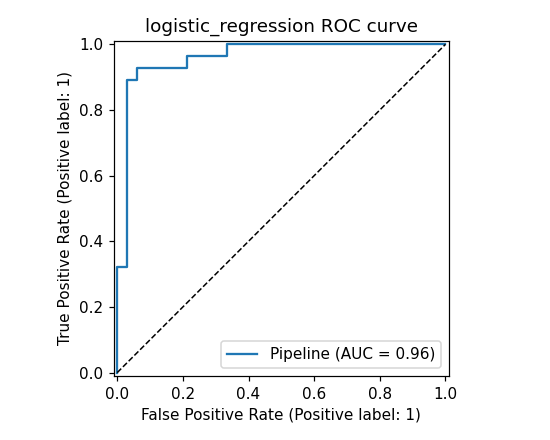

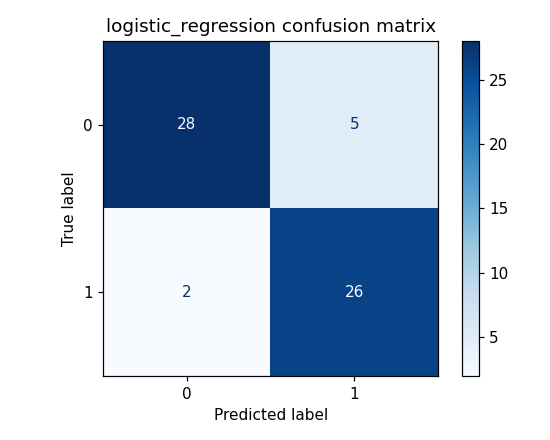

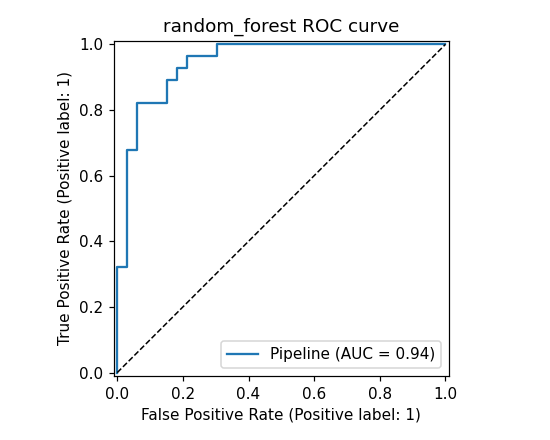

In [7]:
from IPython.display import Image, display
for f in ['logistic_regression_roc_curve.png', 'logistic_regression_confusion_matrix.png', 'random_forest_roc_curve.png']:
    display(Image(filename=str(ROOT / 'report' / 'figures' / f)))

### Model choice
Logistic Regression wins on cross-validated ROC-AUC and is the easier model to explain, which matters for a clinical use case. Random Forest gives no improvement on 303 rows. The full fitted pipeline (preprocessing + model) is saved to `models/model.joblib`, so serving applies exactly the same transforms.

In [8]:
lr = summary['models']['logistic_regression']
import joblib
m = joblib.load(ROOT / 'models' / 'model.joblib')
coef = pd.Series(m.named_steps['model'].coef_[0], index=m.named_steps['preprocess'].get_feature_names_out())
coef.sort_values(key=abs, ascending=False).head(12).round(3)

num__ca         0.703
cat__cp_4       0.536
cat__thal_7     0.503
cat__thal_3    -0.479
cat__sex_1      0.386
cat__sex_0     -0.386
num__thalach   -0.321
cat__slope_2    0.301
cat__cp_3      -0.281
cat__exang_1    0.266
cat__exang_0   -0.266
cat__slope_1   -0.255
dtype: float64